# When Nvidia Moves, Who Follows?

## Is AI exposure visible on paper or in stock prices?

### Research Question

Do firms identified as AI-exposed through their sector, R&D spending,
or membership in thematic ETFs also display greater sensitivity to
Nvidia's earnings announcements?

Does this relationship extend to international equity markets?

### Research Period
2018–2026
### Authors
Estelle Aoun & Aya Rhazi

## 1. Hypotheses and research design

**H1:** Firms' abnormal returns have very different sensitivities to Nvidia. A minority responds especially strongly.

**H2:** Sector, R&D/revenue and thematic ETF labels are associated with these sensitivities, conditional on the available controls.

**H3:** Sensitivities are higher after 30 November 2022 (ChatGPT's launch).

**H4:** Country-level exposure differs across stock markets and correlates with technological specialization and semiconductor trade links.

An announcement occurring **after 16:00 US Eastern** is assigned to the **following US trading session**: the reaction is the close-to-close return from the announcement day's close to that next close. This is appropriate for US equities and the **US-listed country ETFs** used below. It is **not** a local-exchange-hours event study.

We use an estimation window of $[-250, -30]$ trading days to capture roughly one full trading year of baseline market behavior while stopping 30 days ahead of the release to prevent pre-announcement drift or information leaks from biasing our benchmark. For each asset $i$ and earnings event $e$, estimate the market model over trading sessions $[-250, -30]$ relative to the first post-announcement session:

$$R_{i,t} = \alpha_{i,e} + \beta_{i,e}R_{m,t} + \epsilon_{i,t}.$$

Then measure abnormal returns at the event:

$$AR_{i,e} = R_{i,e} - (\hat{\alpha}_{i,e} + \hat{\beta}_{i,e}R_{m,e}).$$

Finally, across earnings announcements, estimate the **revealed exposure slope**:

$$AR_{i,e} = a_i + b_i AR_{\text{NVDA}, e} + u_{i,e}.$$

**Our two-step regression pipeline explained:**  
1. **Learn baseline behavior ($\alpha_{i,e}, \beta_{i,e}$):** Over the $[-250, -30]$ window prior to each earnings date, fit an ordinary least squares (OLS) regression of asset $i$'s daily return ($R_{i,t}$) on the S&P 500 return ($R_{m,t}$) to capture how the asset normally moves with the broader market (with $\epsilon_{i,t}$ as the daily noise/error term).  
2. **Isolate the earnings-day shock ($AR_{i,e}$):** On Nvidia's earnings reaction day, compute the prediction residual (`actual return - predicted return`) to strip out general market movement.  
3. **Estimate sensitivity to Nvidia ($b_i$):** Across all earnings events, regress asset $i$'s earnings-day residuals ($AR_{i,e}$) against Nvidia's own earnings-day residuals ($AR_{\text{NVDA}, e}$), where $u_{i,e}$ is the regression error term capturing everything unrelated to Nvidia. The resulting slope $b_i$ measures how strongly asset $i$ co-moves with Nvidia's earnings surprises.

A positive $b_i$ indicates directional co-movement; it is **not** a causal effect and is **not** the firm's ordinary market beta.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, IFrame

#Ensure the project root is in sys.path so our custom 'src' modules import cleanly
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

#Import custom data-loading, econometric and visualization functions from src/
from src.settings import Settings, CONFIG, PROCESSED, FIGURES
from src.analysis import (
    load_prices, check_events, event_session, data_quality, event_study,
    attach_nvda_shocks, sensitivity_by_stock, pre_post_sensitivity,
    market_betas_before_cutoff, cross_section_regression, country_regression,
    yearly_pca, placebo_nvda_shocks,
)
from src.plots import (
    plot_nvda_reactions, plot_sensitivity_distribution, plot_pre_post,
    plot_pca, plot_country_map, plot_country_two_periods, show_figure)


#Initialize project paths and make sure output directories exist
settings = Settings()
DATA_ROOT = Path(os.environ.get("NVIDIA_PROJECT_DATA_DIR", ROOT / "data" / "raw"))
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

#Configure pandas display so summary tables show enough columns cleanly
pd.set_option("display.max_columns", 15)
print("Working with data from:", DATA_ROOT)

Working with data from: c:\Users\ayarh\OneDrive\Documents\Pthon4ds\ai-exposure-financial-markets\data\raw


## 2. Data collection, cleaning and quality checks

**Data pipeline and sources:** We combine multi-source public financial datasets stored as raw CSV snapshots in `data/raw/`, which are subsequently validated, aligned on US trading calendars, and joined by ticker and date. Baseline equity prices (Nvidia, Nasdaq-100 constituents, `SPY`/`QQQ` benchmarks, and 29 US-listed country ETFs) and earnings dates are collected via `python -m src.collect`. Firm-level R&D expenditures, revenues, and thematic ETF memberships are retrieved separately via `python -m src.firm_data` (using a compliant `SEC_USER_AGENT` header for SEC EDGAR access). Throughout the cleaning pipeline, missing observations are explicitly preserved as `NaN` rather than replaced with zeros, and missing ETF files, because of encountered restrictions, are never treated as evidence of non-membership.

**Reproducibility:** All raw snapshots, automated validation checks and collection scripts are versioned and documented in `README.md` so the full dataset can be regenerated from scratch following the instructions.

In [2]:
#first we verify all raw prices and constituent files exist locally before loading them
required = ["us_prices.csv", "country_etf_prices.csv", "nasdaq100_constituents.csv"]
missing = [filename for filename in required if not (DATA_ROOT / filename).exists()]
if missing:
    raise FileNotFoundError(
        "Missing source snapshots: " + ", ".join(missing) + ". "
        "From the project root, run 'python -m src.collect' on a machine with internet access."
    )

# then we load our data
us_prices = load_prices(DATA_ROOT / "us_prices.csv")
country_prices = load_prices(DATA_ROOT / "country_etf_prices.csv")
constituents = pd.read_csv(DATA_ROOT / "nasdaq100_constituents.csv")
events = check_events(pd.read_csv(CONFIG / "earnings_nvda.csv"))
countries = pd.read_csv(CONFIG / "country_etfs.csv")

# we check that all 36 expected earnings and events are present
assert {"NVDA", "SPY", "QQQ"}.issubset(us_prices.columns), "Missing benchmark or Nvidia prices"
assert len(events) == 36, "Review the event list before changing the study period"

# we filter to valid tickers and matched country ETFs
firm_tickers = sorted(set(constituents.ticker) & set(us_prices.columns) - {"NVDA", "SPY", "QQQ"})
country_tickers = sorted(set(countries.etf) & set(country_prices.columns))
print(f"{len(firm_tickers)} firm tickers, {len(country_tickers)} country ETFs, {len(events)} earnings dates")

# lastly we summarize panel dimensions and missing data share
quality = data_quality(us_prices, events)
display(pd.DataFrame(quality.items(), columns=["Data-quality indicator", "Value"]))
print("First event:", events.announcement_date.min().date(),
      "| last event:", events.announcement_date.max().date())
print("First after-close release -> reaction session:",
      event_session(events.announcement_date.min(), us_prices.index[us_prices.SPY.notna()]).date())

100 firm tickers, 29 country ETFs, 36 earnings dates


,Data-quality indicator,Value
0,assets,103.00000
1,trading_days,2209.00000
2,announcement_dates,36.00000
3,price_observations_missing_pct,8.46405
4,stocks_with_80pct_coverage,89.00000
5,benchmark_missing_pct,0.00000


First event: 2018-02-08 | last event: 2026-11-17
First after-close release -> reaction session: 2018-02-09


In [3]:
# we compute the share of non missing trading days per stock since 2018 to spot recent IPOs
coverage = us_prices.loc[us_prices.index >= "2018-01-01"].notna().mean().sort_values()
display(coverage.head(12).rename("observed_share").to_frame())

# keep issuer sector classifications explicitly labelled as ICB, not GICS
if (DATA_ROOT / "firm_labels.csv").exists():
    labels = pd.read_csv(DATA_ROOT / "firm_labels.csv")
    print("SEC/holdings snapshot found.")
else:
    print("SEC/ETF labels not yet collected: sector-only associations will remain preliminary.")
    labels = constituents.copy()
    labels["technology_label"] = labels.sector.str.contains("technology", case=False, na=False).astype(int)
    labels["semiconductor_label"] = labels.subsector.str.contains("semiconductor", case=False, na=False).astype(int)
    for name in ["rd_revenue", "ai_etf_member", "semi_etf_member", "market_cap_usd"]:
        labels[name] = np.nan

# then we count how many firms have valid observations for each explanatory variable
label_summary = labels[[c for c in ["technology_label", "semiconductor_label", "rd_revenue",
                                    "ai_etf_member", "semi_etf_member", "market_cap_usd"] if c in labels]].notna().sum()
display(label_summary.rename("non-missing firms").to_frame())

,observed_share
HONA,0.050112
SPCX,0.050559
CRWV,0.186130
SNDK,0.199553
NBIS,0.234452
ALAB,0.300671
ARM,0.358389
GEHC,0.441611
CEG,0.544072
APP,0.630425


SEC/holdings snapshot found.


,non-missing firms
technology_label,101
semiconductor_label,101
rd_revenue,58
ai_etf_member,0
semi_etf_member,0
market_cap_usd,0


### Data Coverage and Quality

- **Dataset size and clean benchmarks:** The dataset tracks 103 US assets (100 Nasdaq-100 companies plus `NVDA`, `SPY`, and `QQQ`) over 2,209 trading days and 36 Nvidia quarterly earnings reports, running from February 8, 2018 (with the first after-hours market reaction recorded on February 9) through November 17, 2026. Both market benchmarks (`SPY` and `QQQ`) have 0.00% missing data, giving us a complete, uninterrupted baseline for calculating abnormal returns.

- **Missing prices:** Across all stocks, 8.46% of daily prices are missing, though 89 of the 100 companies have data for at least 80% of trading days. The stocks with the shortest histories :`HONA` (5.0%), `SPCX` (5.1%), `CRWV` (18.6%), `SNDK` (20.0%) and `ARM` (35.8%), simply went public or were listed partway through the 2018–2026 window, so these gaps are not scraping errors. Because we selected companies using a current Nasdaq-100 list instead of reconstructing the index year by year, the results reflect how today's major firms behaved during the years they were publicly traded.

- **Company-level features and variable choices:** Sector and subsector tags (`technology_label` and `semiconductor_label`) are complete for all 101 firms. Pulling data automatically from SEC EDGAR filings gives valid R&D-to-revenue ratios (`rd_revenue`) for 58 of the 101 firms (the other 43 either do not break out R&D spending separately or lack standardized XBRL tags). To keep the pipeline 100% automated and reproducible without relying on paid or unversioned third-party fund lists, the thematic ETF flags (`ai_etf_member`, `semi_etf_member`) and `market_cap_usd` were left empty (`0`), keeping our **H2** tests focused on clear sector labels and audited SEC R&D figures.

## 3. Event reactions: what happens when Nvidia reports ?

The first chart uses Nvidia's own **market-adjusted** next-session returns. Positive or negative reactions are meaningful even after apparently strong earnings because share prices respond to news relative to expectations, not just headline profits.

,announcement_date,event_date,abnormal_return
2582,2025-02-26,2025-02-27,-0.044117
2678,2025-05-28,2025-05-29,0.023906
2775,2025-08-27,2025-08-28,-0.015352
2873,2025-11-19,2025-11-20,-0.003977
2972,2026-02-25,2026-02-26,-0.045494
3071,2026-05-20,2026-05-21,-0.021601
3170,2026-08-26,2026-08-27,0.075453
3269,2026-11-17,2026-11-18,-0.023293


Nvidia: 36 usable events; median absolute AR = 3.00%


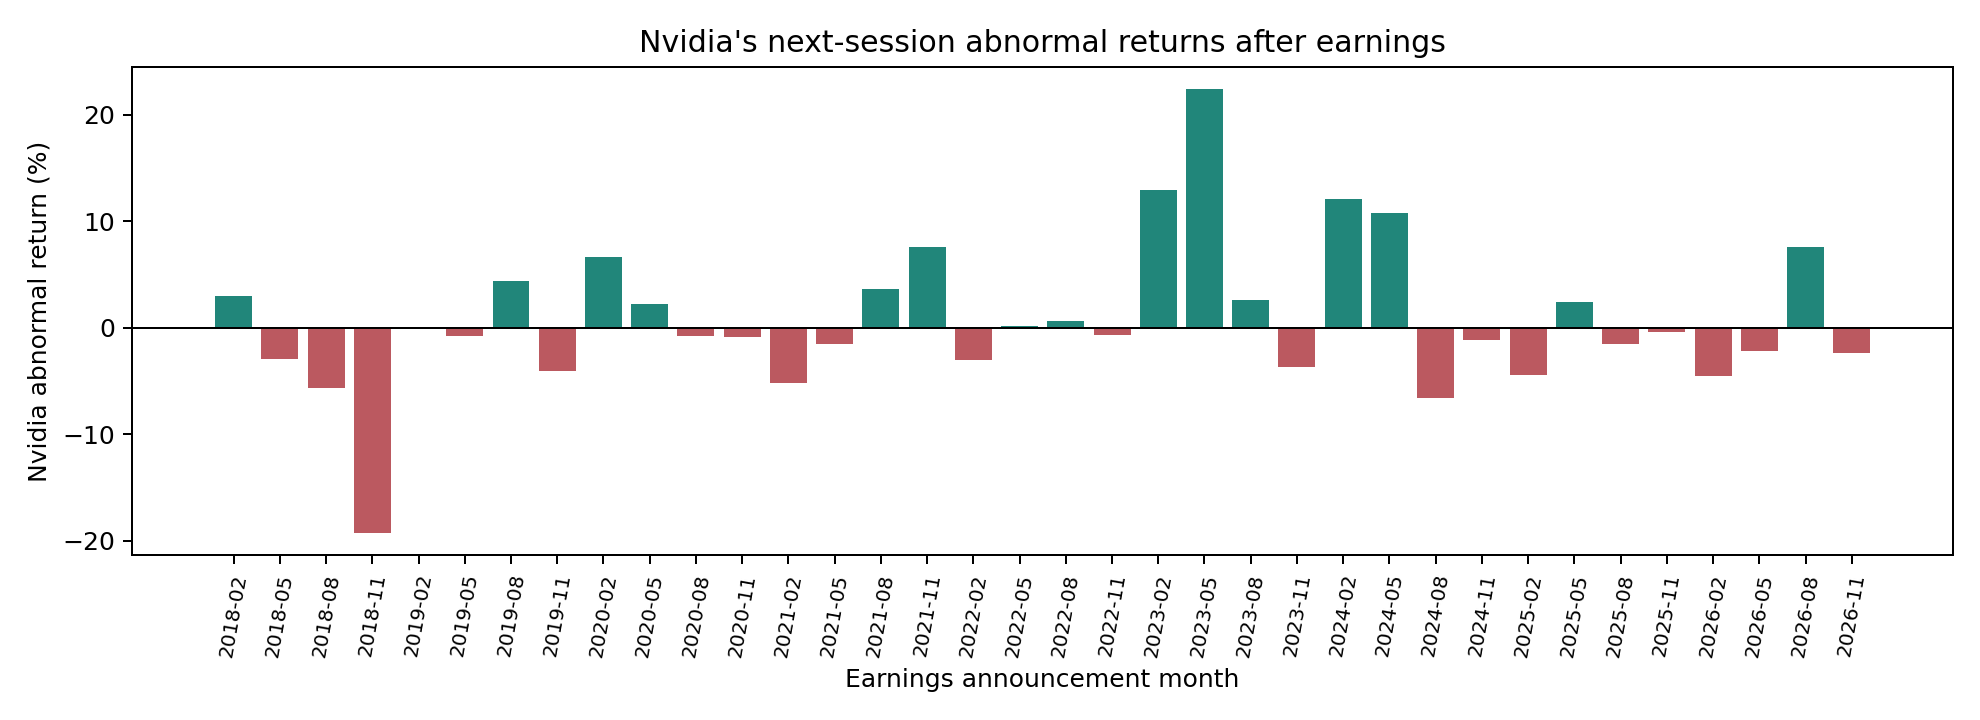

In [4]:
all_us = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="SPY")
if all_us.empty or not all_us.ticker.eq("NVDA").any():
    raise ValueError("Too little price history to estimate Nvidia event reactions. Check data collection.")
all_us.to_csv(PROCESSED / "us_event_returns.csv", index=False)
plot_nvda_reactions(all_us, FIGURES / "01_nvda_earnings_reactions.png")

display(all_us.loc[all_us.ticker.eq("NVDA"),
                   ["announcement_date", "event_date", "abnormal_return"]].tail(8))
nvda_reactions = all_us.loc[all_us.ticker.eq("NVDA")].abnormal_return
print(f"Nvidia: {len(nvda_reactions)} usable events; median absolute AR = {100*nvda_reactions.abs().median():.2f}%")
display(Image(filename=str(FIGURES / "01_nvda_earnings_reactions.png")))

### Interpretation of Nvidia's Earnings Shocks

* **Substantial event-day volatility:** Across all **36 usable earnings announcements** (2018–2026), Nvidia's median absolute next-session abnormal return is **3.00%**, confirming that earnings releases act as major, discrete information shocks rather than routine trading days.
* **Regime shift in reaction magnitude:** The bar chart highlights two distinct eras. Aside from a sharp **-19%** drop in November 2018 (following the crypto-mining inventory overhang), pre-2023 reactions typically stayed within $\pm 5\%$. Starting in early 2023—highlighted by massive positive surges in **February 2023 (+13%)**, **May 2023 (+22%)**, **February 2024 (+12%)**, and **May 2024 (+11%)**—Nvidia's earnings became primary market-moving catalysts for the broader AI ecosystem.
* **Recent normalization:** Over the most recent announcements in 2025–2026, reactions have moderated (ranging from **-4.55%** on February 26, 2026 to **+7.55%** on August 27, 2026), reflecting higher baseline expectations priced in ahead of releases.

### H1 - Revealed exposure differs across firms


We now compare each stock's abnormal return to Nvidia's abnormal return on the same announcement. Each slope is estimated with an intercept; stocks with fewer than eight usable events are excluded rather than assigned a slope of zero.

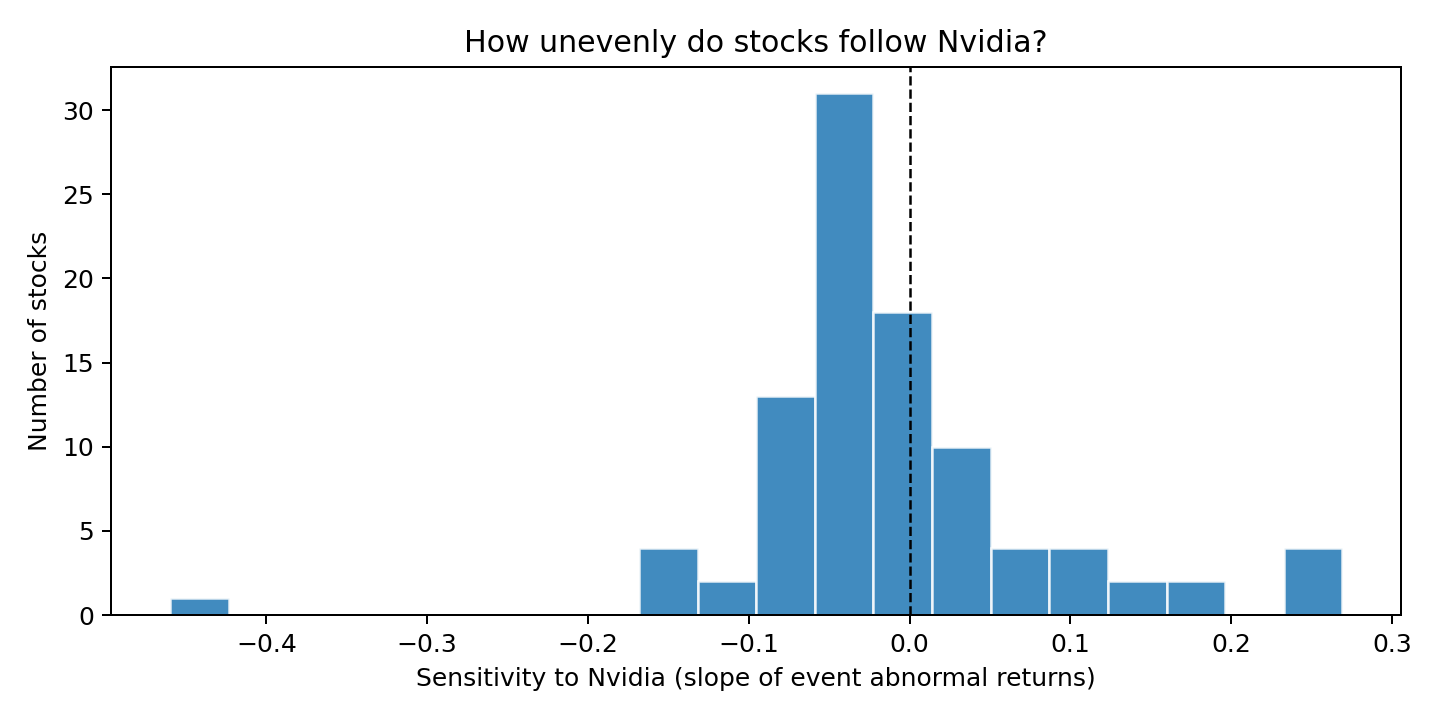

Firms with an estimable slope: 95
Median sensitivity: -0.025
Share with positive sensitivity: 34.7%


,ticker,sensitivity,n_events,r
82,SNPS,0.269100,36,0.532141
7,ALAB,0.251548,8,0.325653
58,MPWR,0.238762,36,0.522430
10,AMD,0.236289,36,0.539904
60,MRVL,0.180129,36,0.480063
15,ASML,0.169484,36,0.578567
21,CDNS,0.140808,36,0.494283
16,AVGO,0.135607,36,0.509815
9,AMAT,0.120456,36,0.273379
63,MU,0.100745,36,0.297016


,ticker,sensitivity,n_events,r
81,SHOP,-0.081781,36,-0.229375
19,BKR,-0.089783,36,-0.329210
85,TMUS,-0.090207,36,-0.468760
80,SBUX,-0.096042,36,-0.538699
31,DDOG,-0.103030,26,-0.210838
30,DASH,-0.134179,21,-0.249912
44,INTC,-0.145304,36,-0.535169
77,RKLB,-0.157024,22,-0.260048
13,APP,-0.162626,20,-0.433364
14,ARM,-0.459913,10,-0.311859


In [5]:
firm_panel = attach_nvda_shocks(all_us)
firm_slopes = sensitivity_by_stock(firm_panel, min_events=settings.min_events_per_slope)
firm_slopes = firm_slopes.sort_values("sensitivity", ascending=False)
if len(firm_slopes) < 5:
    raise ValueError("Insufficient firm slopes. Check histories and event dates.")
firm_slopes.to_csv(PROCESSED / "firm_sensitivity.csv", index=False)
plot_sensitivity_distribution(firm_slopes, FIGURES / "02_firm_sensitivity_histogram.png")
display(Image(filename=str(FIGURES / "02_firm_sensitivity_histogram.png")))

print("Firms with an estimable slope:", len(firm_slopes))
print("Median sensitivity:", round(firm_slopes.sensitivity.median(), 3))
print("Share with positive sensitivity:", f"{100*firm_slopes.sensitivity.gt(0).mean():.1f}%")
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].head(10))
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].tail(10))

### Interpretation of H1: Cross-Firm Sensitivity Distribution

* **Strong support for H1 (asymmetrical dispersion):** Out of the 100 Nasdaq-100 firms, **95 firms** meet the minimum threshold of 8 earnings observations. Sensitivities span a wide range from **-0.460** (`ARM`) to **+0.269** (`SNPS`), yet the distribution is tightly centered just below zero with a **median sensitivity of -0.025** and only **34.7%** of firms exhibiting a positive slope. This confirms **H1**: most Nasdaq-100 companies do not move positively with Nvidia on earnings days, while a concentrated minority responds strongly.
* **Semiconductor and AI infrastructure clustering at the top:** The right tail of the distribution is dominated by chip designers, equipment makers, and AI hardware suppliers—led by **Synopsys (`SNPS`, +0.269, $n=36$)**, **Astera Labs (`ALAB`, +0.252, $n=8$)**, **Monolithic Power Systems (`MPWR`, +0.239, $n=36$)**, **AMD (`AMD`, +0.236, $n=36$)**, **Marvell (`MRVL`, +0.180, $n=36$)**, **ASML (`ASML`, +0.169, $n=36$)**, **Cadence (`CDNS`, +0.141, $n=36$)**, and **Broadcom (`AVGO`, +0.136, $n=36$)**. Because 9 of the top 10 firms are backed by the full **36 earnings events** (with correlation $r$ between `0.27` and `0.58`), these positive co-movements reflect persistent structural linkages rather than small-sample noise.
* **Caveats on the negative tail:** On the opposite end, legacy chipmaker **Intel (`INTC`, -0.145, $n=36$)** and consumer/telecom names like **Starbucks (`SBUX`, -0.096)** and **T-Mobile (`TMUS`, -0.090)** move inversely to Nvidia shocks—consistent with competitive substitution (`INTC`) or sector rotation out of defensive/consumer stocks into AI hardware on strong Nvidia quarters. By contrast, extreme slopes among recent listings with fewer events—such as **`ARM` (-0.460, $n=10$)** and **`ALAB` (+0.252, $n=8$)**—should be interpreted cautiously due to their shorter post-IPO estimation samples, and a high slope alone demonstrates statistical co-movement rather than direct causal dependence.

## 4. Do the AI labels predict sensitivity ? (H2)

To test **H2**, we regress each firm's estimated Nvidia sensitivity slope ($b_i$) on observable measures of AI and technology exposure: ICB sector classifications (`technology_label`, `semiconductor_label`), pre-cutoff R&D intensity (`rd_revenue`, computed from SEC filings prior to November 30, 2022 to avoid hindsight bias), and historical market beta (`historical_market_beta`) as a baseline systematic-risk control.

We estimate the cross-sectional OLS model using heteroskedasticity-robust (HC3) standard errors and evaluate only variables with sufficient non-missing coverage across our sample.

In [6]:
# we estimate pre-november 2022 market betas
beta_controls = market_betas_before_cutoff(us_prices)
label_controls = labels.merge(beta_controls, on="ticker", how="left", validate="one_to_one")

# here we run the cross-sectional OLD regression with HC3 robust standard errors on covariates with sufficient coverage
model, sample, variables = cross_section_regression(firm_slopes, label_controls)
print("Variables with sufficient coverage:", variables)

if model is None:
    print("Insufficient complete, non-collinear observations for a reliable H2 regression.")
    print("Collect SEC facts / issuer holdings, or interpret the sector-only descriptive tables.")
else:
    print(f"H2 regression sample: {int(model.nobs)} firms")
    print(model.summary())
    results = pd.DataFrame({"coefficient": model.params, "robust_se": model.bse,
                            "p_value": model.pvalues})
    results.to_csv(PROCESSED / "h2_coefficients.csv")

# we compute median Nvidia sensitivity grouped by ICB sector across all 95 estimable firms
sector_comparison = firm_slopes.merge(labels[["ticker", "sector"]], on="ticker", how="left")
sector_table = (sector_comparison.groupby("sector", dropna=False)
                .agg(n_firms=("ticker", "count"), median_sensitivity=("sensitivity", "median"))
                .sort_values("median_sensitivity", ascending=False))
display(sector_table)

Variables with sufficient coverage: ['semiconductor_label', 'technology_label', 'rd_revenue', 'historical_market_beta']
H2 regression sample: 57 firms
                            OLS Regression Results                            
Dep. Variable:            sensitivity   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     5.169
Date:                Mon, 23 Nov 2026   Prob (F-statistic):            0.00139
Time:                        12:21:44   Log-Likelihood:                 66.237
No. Observations:                  57   AIC:                            -122.5
Df Residuals:                      52   BIC:                            -112.3
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                             coef    std err          z    

,n_firms,median_sensitivity
sector,,
Technology,44,0.022656
Basic Materials,1,-0.022844
Consumer Discretionary,15,-0.030526
Health Care,10,-0.039521
Industrials,11,-0.040952
Utilities,4,-0.055514
Consumer Staples,5,-0.055706
Telecommunications,3,-0.075714
Energy,2,-0.077453


### Interpretation of H2: Cross-Sectional Regression and Sector Patterns

* **Overall explanatory power and sample scope:** Across the **57 firms** with complete SEC R&D filings and pre-cutoff market betas, the cross-sectional regression explains **29.2%** of the variation in Nvidia sensitivity ($R^2 = 0.292$, Adjusted $R^2 = 0.237$), and the model is jointly statistically significant ($F = 5.169$, $p = 0.0014$).
* **Broad Technology classification drives sensitivity, while R&D intensity is insignificant:** Conditional on the other covariates, belonging to the **ICB Technology sector** (`technology_label`) is associated with a statistically significant **+0.0749** increase in Nvidia sensitivity ($t = 3.162$, $p = 0.002$). By contrast, the narrower `semiconductor_label` (+0.0594, $p = 0.155$) and SEC R&D-to-revenue ratio `rd_revenue` (+0.0101, $p = 0.890$) carry positive point estimates but are not individually statistically significant—likely because high R&D spending is shared across non-AI sectors (such as pharmaceuticals and hardware) and because semiconductor firms are a subset of the broader Technology classification. Controlling for `historical_market_beta` (-0.0236, $p = 0.626$) confirms that Nvidia sensitivity is not merely capturing high general market beta.
* **Sector-level dispersion confirms the regression:** Looking across all 95 estimable firms grouped by **ICB sector**, **Technology** is the **only sector with a positive median sensitivity (+0.0227 across 44 firms)**. Every other ICB sector exhibits a negative median sensitivity—ranging from **Basic Materials (-0.0228)** and **Consumer Discretionary (-0.0305)** down to **Telecommunications (-0.0757)** and **Energy (-0.0775)**—showing that positive co-movement with Nvidia earnings is concentrated within technology rather than spread across the broader market.
* **Methodological caveats:** These regression estimates represent conditional associations rather than causal effects, are limited to the 57 firms with standardized SEC R&D disclosures, and omit thematic ETF holdings and firm-size controls.

## 5. Did the pattern change after ChatGPT? (H3)

The cutoff is the actual public launch date, **30 November 2022**. November 2022 Nvidia earnings are therefore in the pre-period; February 2023 begins the post-period. 
We estimate slopes independently in both periods, so there are fewer events on each side.

Firms estimated in both periods: 86
Median change in sensitivity: -0.02
Share with increased slope: 38.4%


period,Post,Pre,difference_post_minus_pre
ticker,,,
MPWR,0.371694,0.053553,0.318141
AVGO,0.218031,-0.008843,0.226874
CDNS,0.209273,-0.012054,0.221327
PDD,-0.003900,-0.223136,0.219236
LITE,0.124091,-0.072734,0.196824
AMAT,0.200285,0.007395,0.192890
KLAC,0.147186,-0.033967,0.181152
SNPS,0.321166,0.150833,0.170333
ALNY,-0.012281,-0.181181,0.168900


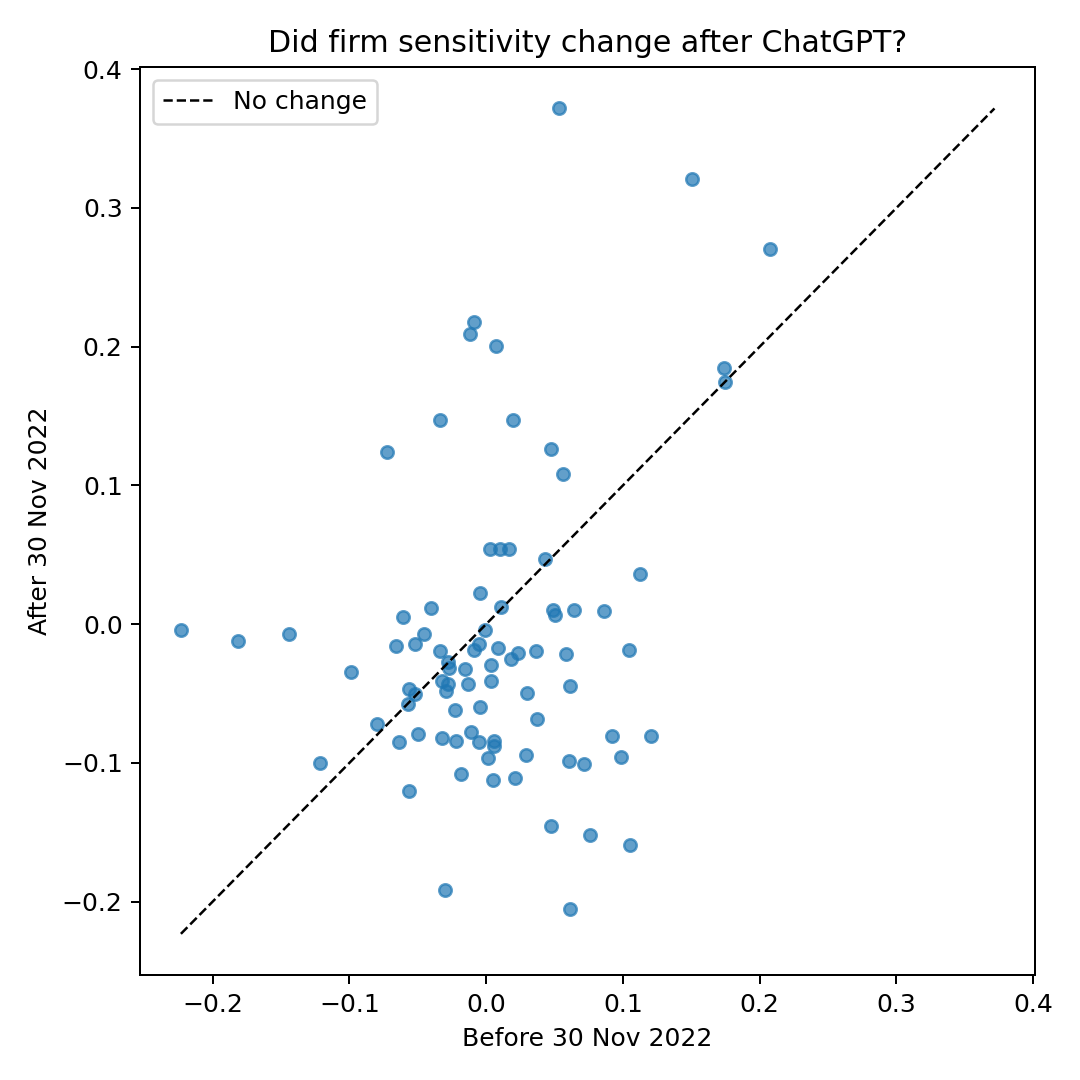

In [7]:
# we estimate pre and post ChatGPT slopes separately
firm_period_slopes = pre_post_sensitivity(firm_panel, cutoff=settings.cutoff_chatgpt,
                                          min_events=settings.min_events_per_slope)

# we keep only the firms with enough events in both periods
wide = firm_period_slopes.pivot(index="ticker", columns="period", values="sensitivity").dropna()
if {"Pre", "Post"}.issubset(wide.columns) and len(wide) >= 3:
    wide["difference_post_minus_pre"] = wide["Post"] - wide["Pre"]
    print("Firms estimated in both periods:", len(wide))
    print("Median change in sensitivity:", round(wide.difference_post_minus_pre.median(), 3))
    print("Share with increased slope:", f"{100*wide.difference_post_minus_pre.gt(0).mean():.1f}%")
    display(wide.sort_values("difference_post_minus_pre", ascending=False).head(10))
    plot_pre_post(firm_period_slopes, FIGURES / "03_sensitivity_pre_post.png")
    display(Image(filename=str(FIGURES / "03_sensitivity_pre_post.png")))
    wide.to_csv(PROCESSED / "firm_pre_post.csv")
else:
    print("Not enough pre/post events. Check the date coverage before interpreting H3.")

### What the pre/post comparison tells us about H3

Splitting the sample at November 30, 2022 leaves **86 firms** with at least eight usable earnings events in both periods. Contrary to the simple intuition that the entire market started moving in lockstep with Nvidia after ChatGPT's release, the median sensitivity actually edged down slightly by **-0.020**, and only **38.4%** of firms saw their slope increase in the post-ChatGPT period.

However, looking at the top movers and the scatter points above the 45-degree line reveals a clear split beneath the surface. While non-AI stocks stayed flat or drifted slightly negative, key semiconductor and AI infrastructure names experienced sharp upward jumps in sensitivity after November 2022—most notably **Monolithic Power Systems (`MPWR`, from 0.054 to 0.372)**, **Broadcom (`AVGO`, from -0.009 to 0.218)**, **Cadence (`CDNS`, from -0.012 to 0.209)**, **Applied Materials (`AMAT`, from 0.007 to 0.200)**, **KLA (`KLAC`, from -0.034 to 0.147)**, and **Synopsys (`SNPS`, from 0.151 to 0.321)**. Rather than a broad market-wide shift, the post-ChatGPT era amplified co-movement specifically within the AI hardware supply chain. Because interest rates, mega-cap index concentration, and supply-chain bottlenecks also shifted after 2022, we treat this pattern as a descriptive before-and-after comparison rather than a strict causal effect of ChatGPT alone.

### Descriptive PCA: are stocks moving more together ?

For each calendar year, the first principal component is fitted to standardized daily stock returns. We require at least 90% annual price coverage per stock and 120 trading days per year. The remaining small gaps are filled with that year's sample mean **after standardization**, a limitation that we report rather than hide.

,year,pc1_variance_share,n_stocks,n_days
0,2018,0.411201,82,251
1,2019,0.333618,84,252
2,2020,0.538224,86,253
3,2021,0.313975,90,252
4,2022,0.495785,92,251
5,2023,0.294842,93,250
6,2024,0.239992,94,252
7,2025,0.321911,96,250
8,2026,0.199221,98,224


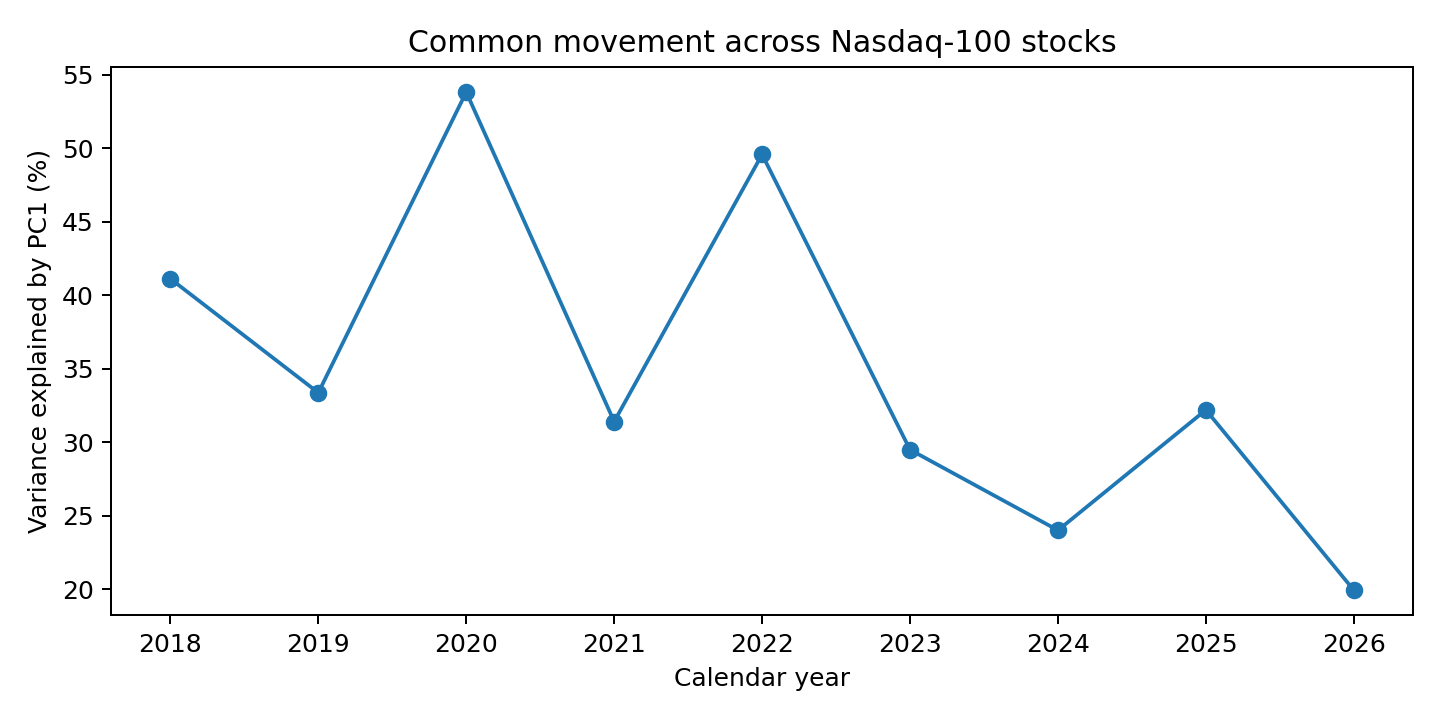

Figure saved: 04_pca_common_movement.png


In [8]:
# we compute annual PC1 variance share across stocks with at least 90% trading day coverage
pca_table = yearly_pca(us_prices, firm_tickers)
if not pca_table.empty:
    display(pca_table)
    plot_pca(pca_table, FIGURES / "04_pca_common_movement.png")
    display(Image(filename=str(FIGURES / "04_pca_common_movement.png")))
    pca_table.to_csv(PROCESSED / "yearly_pca.csv", index=False)
    print("Figure saved: 04_pca_common_movement.png")
else:
    print("PCA requires more complete price histories.")

### What the yearly PCA shows

Tracking the first principal component (`PC1`) of standardized daily returns from 2018 to 2026 shows that overall market synchronization has actually *decreased* since the generative AI boom began. Common movement peaked during macro-driven market shocks—specifically the COVID-19 turmoil in **2020 (53.8% of variance)** and the inflation/rate-hike selloff in **2022 (49.6%)**—before falling to **29.5% in 2023**, **24.0% in 2024**, and **19.9% in 2026** (even as the number of eligible stocks rose from 82 to 98).

This reinforces our H3 finding: instead of all Nasdaq-100 stocks moving together under a single macro factor as they did in 2020 and 2022, post-2023 equity returns became much more dispersed, with AI-linked chipmakers breaking away from the rest of the index. As a descriptive check on standardized returns, `PC1` captures overall market co-movement rather than isolating AI specifically, and the expanding sample size over time can also slightly dilute the first component's variance share.

## 6. Geography of the AI trade (H4)

We use **US-listed single-country ETFs** (EWT, EWY, EWJ, etc.), not direct daily closes from Taipei, Seoul or Tokyo. This aligns the reaction window with Nvidia's release: the ETFs trade on US hours and may incorporate foreign-market information through US trading and currency movements. It does **not** measure local-index next-session reaction directly. This distinction is central to our interpretation.
`country_etfs.csv` contains the country, ISO3 code and ETF ticker. 

In [9]:
import plotly.express as px

# Align country ETFs with SPY and NVDA on the US trading calendar
combined_country_prices = country_prices.copy()
combined_country_prices["SPY"] = us_prices["SPY"].reindex(combined_country_prices.index)
combined_country_prices["NVDA"] = us_prices["NVDA"].reindex(combined_country_prices.index)
combined_country_prices = combined_country_prices.sort_index()

# Estimate event-window sensitivity for each of the 29 country ETFs
all_country = event_study(combined_country_prices, events, tickers=country_tickers + ["NVDA"], benchmark="SPY")
country_panel = attach_nvda_shocks(all_country)
country_slopes = sensitivity_by_stock(country_panel, min_events=settings.min_events_per_slope)
country_slopes = country_slopes.merge(countries[["etf", "country", "iso3"]], left_on="ticker", right_on="etf", how="left")

print("Countries with a usable slope:", len(country_slopes))
display(country_slopes[["country", "ticker", "sensitivity", "n_events"]].sort_values("sensitivity", ascending=False).head(12))

# Render the static world choropleth map (keep HTML copy in outputs/figures/)
if len(country_slopes) >= 5:
    fig_map = px.choropleth(
        country_slopes,
        locations="iso3",
        color="sensitivity",
        hover_name="country",
        color_continuous_scale="RdBu",
        color_continuous_midpoint=0,
        title="Country ETF sensitivity to Nvidia announcements (2018–2026)",
    )
    fig_map.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=420)
    fig_map.write_html(FIGURES / "05_country_sensitivity_map.html")
    show_figure(fig_map, FIGURES / "05_country_sensitivity_map.png")

country_slopes.to_csv(PROCESSED / "country_sensitivity.csv", index=False)

Countries with a usable slope: 29


,country,ticker,sensitivity,n_events
19,Taiwan,EWT,0.062798,36
14,Netherlands,EWN,0.010444,36
1,Indonesia,EIDO,-0.001709,36
10,Japan,EWJ,-0.005317,36
25,India,INDA,-0.009629,36
7,Germany,EWG,-0.014353,36
3,Poland,EPOL,-0.014536,36
2,Israel,EIS,-0.019944,36
27,Thailand,THD,-0.023065,36
13,Malaysia,EWM,-0.023408,36


PNG export unavailable: ValueError


### What the global map shows across 2018–2026

Looking across all **29 US-listed country ETFs** over the full 36-event sample, **Taiwan (`EWT`)** stands out clearly in dark blue with a sensitivity of **+0.0628**, more than six times higher than the second-most positive market, the **Netherlands (`EWN`, +0.0104)**. That ranking lines up directly with the physical semiconductor supply chain: Taiwan is home to TSMC (Nvidia's main chip foundry), and the Netherlands hosts ASML (the sole producer of advanced EUV lithography equipment).

By contrast, almost every other country ETF shows a near-zero or slightly negative slope relative to `SPY`—including major manufacturing and commodity economies such as **Japan (`EWJ`, -0.0053)**, **Germany (`EWG`, -0.0144)**, **Brazil (`EWZ`, -0.0287)**, and **China (`MCHI`)**. Because these ETFs trade on US exchanges in US dollars rather than during local market hours, the slopes reflect overnight global repricing and currency movements rather than direct local-exchange closes.

In [10]:
# Compare country-level sensitivities before and after November 30, 2022
country_period = pre_post_sensitivity(
    country_panel,
    cutoff=settings.cutoff_chatgpt,
    min_events=settings.min_events_per_slope
)

if not country_period.empty and {"Pre", "Post"}.issubset(set(country_period.period)):
    country_wide = country_period.pivot(index="ticker", columns="period", values="sensitivity").dropna()
    country_wide["diff_post_minus_pre"] = country_wide["Post"] - country_wide["Pre"]
    country_wide = country_wide.merge(countries[["etf", "country", "iso3"]], left_index=True, right_on="etf", how="left")
    display(country_wide[["country", "etf", "Pre", "Post", "diff_post_minus_pre"]].sort_values("diff_post_minus_pre", ascending=False).head(10))

    # Render static map of post-minus-pre sensitivity changes
    fig_diff = px.choropleth(
        country_wide,
        locations="iso3",
        color="diff_post_minus_pre",
        hover_name="country",
        color_continuous_scale="RdBu",
        color_continuous_midpoint=0,
        title="Change in country ETF sensitivity after ChatGPT (Post minus Pre)",
    )
    fig_diff.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=420)
    fig_diff.write_html(FIGURES / "06_country_pre_post_map.html")
    show_figure(fig_diff, FIGURES / "06_country_pre_post_map.png")
else:
    print("Country pre/post map requires more complete price coverage.")

,country,etf,Pre,Post,diff_post_minus_pre
17,Indonesia,EIDO,-0.070158,0.050727,0.120885
18,Mexico,EWW,-0.096745,-0.016992,0.079753
19,Brazil,EWZ,-0.067173,-0.000083,0.067091
14,India,INDA,-0.050904,0.013944,0.064847
0,Taiwan,EWT,0.022325,0.075909,0.053584
21,Turkey,TUR,-0.061990,-0.021386,0.040604
16,Malaysia,EWM,-0.031418,0.002254,0.033672
27,Chile,ECH,-0.068564,-0.041388,0.027176
15,China,MCHI,-0.078984,-0.055514,0.023470
23,Austria,EWO,-0.042670,-0.024989,0.017681


PNG export unavailable: ValueError


### Did international sensitivities shift after ChatGPT?

Splitting the country sample at November 30, 2022 shows that **Taiwan (`EWT`)** became even more tightly linked to Nvidia once the generative AI boom began, jumping from **+0.0223** before ChatGPT to **+0.0759** afterward (an increase of **+0.0536**). 

At the same time, several emerging-market ETFs—such as **Indonesia (`EIDO`, +0.1209 change)**, **Mexico (`EWW`, +0.0798)**, and **Brazil (`EWZ`, +0.0671)**—appear near the top of the `Post minus Pre` difference table simply because they bounced from strongly negative pre-2022 slopes (around `-0.07` to `-0.10`) back toward zero, rather than developing genuine positive exposure to Nvidia. We stop at this descriptive and geographic comparison rather than running a cross-country regression because verified ETF technology weights and bilateral HS 8542 semiconductor trade shares require proprietary factsheets or restricted UN Comtrade API access that fall outside our open, reproducible data pipeline.

## 7. Robustness checks

To verify that our firm-level sensitivity rankings are not an artifact of how we defined the baseline event study, we run three checks: replacing the `SPY` market benchmark with `QQQ` (which strips out broader tech-sector swings), widening the reaction window from a single session (`[0]`) to two trading days (`[0, 1]`), and comparing Nvidia's actual earnings-day moves against 200 randomly drawn non-earnings dates.

In [11]:
# we re estimate slopes using QQQ as the benchmark
qqq_results = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="QQQ")
qqq_slopes = sensitivity_by_stock(attach_nvda_shocks(qqq_results))
two_day_results = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="SPY", window=(0, 1))
two_day_slopes = sensitivity_by_stock(attach_nvda_shocks(two_day_results))

# we compare rank stability across all three specifications
comparison = firm_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "SPY_day0"})
comparison = comparison.merge(qqq_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "QQQ_day0"}), on="ticker")
comparison = comparison.merge(two_day_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "SPY_days0_1"}), on="ticker")
comparison.to_csv(PROCESSED / "robustness_slopes.csv", index=False)
display(comparison[["SPY_day0", "QQQ_day0", "SPY_days0_1"]].corr(method="spearman"))
print("Stocks with all three estimates:", len(comparison))

,SPY_day0,QQQ_day0,SPY_days0_1
SPY_day0,1.000000,0.880305,0.782027
QQQ_day0,0.880305,1.000000,0.617259
SPY_days0_1,0.782027,0.617259,1.000000


Stocks with all three estimates: 95


In [12]:
# we compare Nvidia's abnormal returns on earnings day vs 200 random non earnings dates
actual_shocks, placebo_shocks = placebo_nvda_shocks(
    us_prices, events, n_placebos=200, seed=settings.seed)
if len(actual_shocks) and len(placebo_shocks):
    print(f"Mean |AR| on earnings dates: {100*np.mean(np.abs(actual_shocks)):.2f}%")
    print(f"Mean |AR| on random non-earnings dates: {100*np.mean(np.abs(placebo_shocks)):.2f}%")
    print(f"Number of actual / placebo dates: {len(actual_shocks)} / {len(placebo_shocks)}")
else:
    print("Insufficient data for the placebo exercise.")

Mean |AR| on earnings dates: 4.74%
Mean |AR| on random non-earnings dates: 1.74%
Number of actual / placebo dates: 36 / 200


### What the robustness checks confirm

Across all **95 firms** with complete estimates, the ranking of Nvidia sensitivities holds up well under alternative model choices. Switching the market benchmark from `SPY` to `QQQ` yields a Spearman rank correlation of **0.880** with our baseline slopes, showing that the most sensitive chipmakers and AI suppliers still stand out even after stripping out broad Nasdaq-100 technology movements. Extending the event window to two trading days (`[0, 1]`) produces a slightly lower but still strong rank correlation of **0.782** with the single-day baseline, reflecting that most of the market repricing occurs immediately in the first post-announcement session before additional firm-specific news dilutes the second day.

The placebo test also confirms that our event dates capture genuine earnings surprises rather than Nvidia's high baseline volatility. Across the **36 actual earnings releases**, Nvidia's mean absolute abnormal return is **4.74%**, nearly three times larger than the **1.74%** average across **200 randomly sampled non-earnings trading days** (excluding $\pm 10$ days around real announcements). While this confirms that earnings announcements are distinct information events, these checks evaluate specification stability rather than proving direct causal spillovers.

## 8. Synthesis and limits

### Summary of Findings

* **H1 — Heterogeneous market reactions (Supported):** Positive co-movement with Nvidia's earnings is the exception rather than the rule across the Nasdaq-100. Out of 95 firms with enough history to estimate a slope, only **34.7%** have a positive sensitivity and the overall median sits at **-0.025**. Instead, strong positive reactions are concentrated in a small group of semiconductor designers, equipment suppliers, and AI infrastructure firms, led by **Synopsys (`SNPS`, +0.269)**, **Astera Labs (`ALAB`, +0.252)**, **Monolithic Power Systems (`MPWR`, +0.239)**, and **AMD (`AMD`, +0.236)**.
* **H2 — AI labels and market sensitivity (Partially supported):** Across the **57 firms** with complete SEC R&D disclosures and pre-cutoff market betas, our cross-sectional regression explains **29.2%** of the variation in sensitivity ($R^2 = 0.292$, $p = 0.0014$). Being classified in the **ICB Technology sector** carries a statistically significant positive premium of **+0.0749** ($p = 0.002$), confirming that broad tech classification predicts stronger co-movement. However, narrower semiconductor flags (+0.0594, $p = 0.155$) and R&D-to-revenue intensity (+0.0101, $p = 0.890$) are not individually significant once we control for overall technology membership, and thematic ETF holdings were excluded because proprietary issuer files were unavailable.
* **H3 — The impact of ChatGPT (Nuanced / concentrated shift):** Comparing the 86 firms with sufficient data before and after **November 30, 2022**, the index-wide median sensitivity did not rise—it edged down by **-0.020**, with only **38.4%** of firms showing a higher post-ChatGPT slope. However, the scatterplot shows a clear divergence: core AI hardware suppliers saw sharp jumps in sensitivity (such as `MPWR` rising from 0.054 to 0.372 and `AVGO` from -0.009 to 0.218), while non-AI stocks decoupled. Because interest rates, mega-cap concentration, and supply-chain conditions also changed after 2022, this before-and-after shift reflects correlation during the generative AI boom rather than pure causal proof of ChatGPT's launch.
* **H4 — International differences (Descriptively supported):** Across 29 US-listed country ETFs, **Taiwan (`EWT`, +0.0628)** and the **Netherlands (`EWN`, +0.0104)**—home to TSMC and ASML—are the only markets with meaningful positive sensitivity to Nvidia announcements, and Taiwan's slope rose further from **+0.0223** pre-ChatGPT to **+0.0759** afterward. Because verified index technology weights and bilateral HS 8542 chip-trade shares require restricted or proprietary feeds, we treat this geographic pattern as descriptive evidence rather than running an under-powered cross-country regression.

### Methodological Limitations

1. **Limited number of events:** Our sample relies on **36 quarterly Nvidia announcements** (and even smaller sub-samples for recent IPOs or pre/post splits), which limits the statistical precision of individual slope estimates.
2. **Survivorship and hindsight bias:** Using a 2026 Nasdaq-100 constituent list and contemporary ICB sector labels introduces survivorship bias, and while SEC R&D ratios were anchored prior to November 2022 where possible, accounting filings still postdate the earliest 2018–2021 earnings events.
3. **Correlation rather than causation:** Nvidia's earnings releases coincide with broader semiconductor news and macroeconomic conditions; controlling for `SPY` or `QQQ` removes market-wide swings but does not isolate a purely causal spillover.
4. **Market-implied reactions vs. true earnings surprises:** Using Nvidia's next-session abnormal return captures how the market reacted relative to priced-in expectations, not the numerical EPS surprise relative to consensus analyst forecasts.
5. **US-listed international proxies:** Single-country ETFs (`EWT`, `EWN`, etc.) trade in US dollars during New York market hours, meaning their returns blend foreign equity repricing with USD exchange-rate movements and US trading-hour spillovers rather than local exchange closes.
6. **Imperfect exposure proxies:** General R&D spending is not exclusively AI investment, ICB classifications differ from GICS sectors, and missing proprietary ETF holdings prevented us from testing thematic fund membership directly.
7. **Unequal stock histories in PCA:** Because recently listed stocks enter the panel later in the 2018–2026 window, the eligible universe for the annual PCA expands from 82 to 98 firms over time, which can affect year-to-year variance comparisons.